python 3.11.12

ultralytics==8.3.107
matplotlib==3.10.0
numpy==2.0.2
opencv-python==4.11.0.86
torch @ https://download.pytorch.org/whl/cu124/torch-2.6.0%2Bcu124-cp311-cp311-linux_x86_64.whl
torchaudio @ https://download.pytorch.org/whl/cu124/torchaudio-2.6.0%2Bcu124-cp311-cp311-linux_x86_64.whl
torchsummary==1.5.1
torchvision @ https://download.pytorch.org/whl/cu124/torchvision-0.21.0%2Bcu124-cp311-cp311-linux_x86_64.whl

In [1]:
from ultralytics import FastSAM
model = FastSAM('FastSAM-x.pt') # FastSAM.pt or FastSAM-s.pt(smaller & less accurate)

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import cv2
import sys
import torch
import time
from scipy.ndimage import gaussian_filter
import os

In [3]:
# extract frames
# Video file to process

video_file = "./data/nb.mp4"
#video_file = "./data/chem.mp4"
output_dir = "./trash"
os.makedirs(output_dir, exist_ok=True)

# Folders in the output directory
# final - list of unique pages in the video file
# frames - all frames in the video file
# pages - pages in all frames
for d in ["frames"]:
    os.makedirs(output_dir + "/" + d, exist_ok=True)

def video_to_frames(video_file):
    vidcap = cv2.VideoCapture(video_file)

    frames = []

    while True:
        success, image = vidcap.read()
        if success:
            frames.append(image)
        else:
            break

    return frames

def save_images(images, output_dir):
    for i, f in enumerate(images):
        cv2.imwrite(f"{output_dir}/{i:05d}.jpg", f)

frames = video_to_frames(video_file)
save_images(frames, output_dir + "/frames")

In [4]:
def find_bounding_box(mask):
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    if not np.any(rows) or not np.any(cols):
        return None  # Handle empty mask case

    min_row, max_row = np.where(rows)[0][[0, -1]]
    min_col, max_col = np.where(cols)[0][[0, -1]]
    #return min_row, max_row, min_col, max_col
    return min_col, min_row, max_col-min_col, max_row-min_row

def genfs_numpy(image):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    eres = model(image, device=device, retina_masks=True, imgsz=1024, conf=0.4, iou=0.9)
    masks_cpu = eres[0].masks.data.cpu().detach().numpy()
    xyxy = eres[0].boxes.xyxy.cpu().detach().numpy().astype(int)

    ret = []
    for i in range(0, len(masks_cpu)):
        ret.append({
            'segmentation': masks_cpu[i],
            #'bbox': [xyxy[i][0], xyxy[i][1], xyxy[i][2]-xyxy[i][0], xyxy[i][3]-xyxy[i][1]],
            'bbox': find_bounding_box(masks_cpu[i]),
            'xyxy': xyxy[i],
            'area': np.count_nonzero(masks_cpu[i] == 1), # torch.sum(masks_cpu[i] == 1) when using tensors
        })

    return sorted(ret, key=(lambda x: x['area']), reverse=True)

In [5]:
# Image plotting utils

def show_anns(anns):
    if len(anns) == 0:
        return
    ax = plt.gca()
    #ax.set_autoscale_on(False)

    img = np.ones((anns[0]['segmentation'].shape[0], anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0
    for ann in anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m==1] = color_mask
    ax.imshow(img)

def draw_rectangle(anns, color='r', linewidth=2):
    ax = plt.gca()
    for ann in anns:
        x, y, w, h = ann['bbox']
        rect = patches.Rectangle((x, y), w, h, linewidth=linewidth, edgecolor=color, facecolor='none')
        ax.add_patch(rect)

In [6]:
# Process output from sam utils

# Filter out the masks to get the list of potential page(s)
# Return of a list of masks that are potential pages
# Consider the masks whose area > apct * frame_size
# Accept a mask that has < X (area * fpct) number of False inside the bbox
def get_pages(masks, apct, fpct):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size
    for m in masks:
        if m['area'] > frame_size * apct:
            bbox = m['bbox']
            num_falses = np.count_nonzero(m['segmentation'][bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == False)
            if num_falses < m['area'] * fpct:
                p.append(m)
    return p

# If two pages are in a frame, then there maybe 3 segments
# 1. covering both pages
# 2. page 1
# 3. page 2
# Filter out the page #1, since the bbox is covered by #2 + #3
def filter_covered_pages(pages, tpct):
    filtered = []
    if len(pages) == 0:
        return filtered
    elif len(pages) <= 2:
        return pages


    img_mask = np.full(pages[0]['segmentation'].shape, False)

    for p in sorted(pages, key=(lambda x: x['area'])):
        bbox = p['bbox']
        num_trues = np.count_nonzero(img_mask[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == True)
        if num_trues < p['area'] * tpct:
            filtered.append(p)
        img_mask[p['segmentation'] == 1] = True
    return filtered

# finds mask with area in range
def in_area_range(masks, apct, amx):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size
    for m in masks:
        if m['area'] > frame_size * apct and m['area'] < frame_size * amx:
            p.append(m)
    return p

# uses upper and lower size bound
def find_pages_nb(masks, apct, amx, fpct):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size
    for m in masks:
        if m['area'] > frame_size * apct and m['area'] < frame_size * amx:
            bbox = m['bbox']
            num_falses = np.count_nonzero(m['segmentation'][bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == False)
            if num_falses < m['area'] * fpct:
                p.append(m)
    return p

In [7]:
imgp = frames[len(frames)-1]
masks = genfs_numpy(imgp)


0: 576x1024 6 objects, 100.2ms
Speed: 16.2ms preprocess, 100.2ms inference, 543.8ms postprocess per image at shape (1, 3, 576, 1024)


2


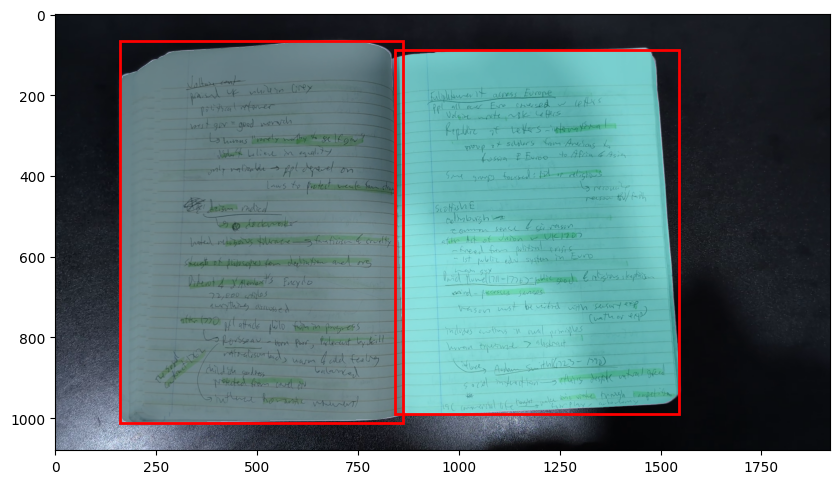

In [8]:
#pgs = masks
#pgs = filter_covered_pages(get_pages(masks, 0.20, 0.10), 0.20)
pgs = filter_covered_pages(find_pages_nb(masks, 0.20, 0.50, 0.10), 0.20)
#pgs = find_pages_nb(masks, 0.20, 0.50, 0.20)
#pgs = in_area_range(masks, 0.20, 0.50)
print(len(pgs))

plt.figure(figsize=(10,10))
plt.imshow(imgp)
#plt.axis('off')
show_anns(pgs)
draw_rectangle(pgs, color='r', linewidth=2)
plt.show()

In [9]:
# Test on full video

stt = time.time()
fin_pg = []
dire = 'trash/frames/'
for i in range(0, len(frames)):
    il = str(i) + '.jpg'
    while len(il) != 9:
        il = "0" + il
    fn = dire+il

    masks = genfs_numpy(fn)

    #pgs = find_pages_nb(masks, 0.20, 0.50, 0.20)
    #pgs = filter_covered_pages(get_pages(masks, 0.20, 0.10), 0.20)
    pgs = filter_covered_pages(find_pages_nb(masks, 0.20, 0.50, 0.10), 0.20)
    fin_pg.append(pgs)
print("PREDICTION TOOK: ", time.time()-stt, "seconds")


image 1/1 /mnt/c/Users/dumbo/code/flipatron/trash/frames/00000.jpg: 576x1024 6 objects, 91.5ms
Speed: 5.3ms preprocess, 91.5ms inference, 7.3ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /mnt/c/Users/dumbo/code/flipatron/trash/frames/00001.jpg: 576x1024 6 objects, 79.6ms
Speed: 4.6ms preprocess, 79.6ms inference, 13.8ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /mnt/c/Users/dumbo/code/flipatron/trash/frames/00002.jpg: 576x1024 7 objects, 76.6ms
Speed: 4.1ms preprocess, 76.6ms inference, 7.7ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /mnt/c/Users/dumbo/code/flipatron/trash/frames/00003.jpg: 576x1024 6 objects, 74.2ms
Speed: 5.1ms preprocess, 74.2ms inference, 7.0ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /mnt/c/Users/dumbo/code/flipatron/trash/frames/00004.jpg: 576x1024 6 objects, 74.8ms
Speed: 6.8ms preprocess, 74.8ms inference, 7.3ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /mnt/c/Users/dumbo

In [10]:
# Find if the pages are mono increasing then mono decreasing to check if anything is blocking a page
# slope over range is (slope) <-- filter for noise from sam

# OPTMIZE W NUMPY FUNCS
def mono(mask, rnge, slope):
    frs = mask['segmentation']
    for n4 in range(0, 4):
        ft = []
        for i in frs:
            first1 = np.argmax(i)
            first1 = first1 if i[first1] != 0 else len(i)
            ft.append(first1)

        fi = False
        for i in range(0, len(ft)-rnge):
            if abs(ft[i] - ft[i+rnge])/rnge > slope:
                if ft[i+rnge] > ft[i]:
                    fi = True
                elif fi:
                    return False
        frs = np.rot90(frs)

    return True

In [14]:
stt = time.time()

is_notebook = True # If you are trying to scan individual pages, make this False

goodpg = []
for i in fin_pg:
    # Need 2 pages if you are finding a notebook and 1 page if finding individual pages
    if is_notebook:
        g = (len(i) == 2)
    else:
        g = (len(i) == 1)
    for j in i:
        g = (g and mono(j, 10, 0.50))
#        g = (g and mono(j, 2, 10))
    goodpg.append(g)

print("PREDICTION TOOK: ", time.time()-stt, "seconds")
print(goodpg)

PREDICTION TOOK:  2.7999155521392822 seconds
[True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]


PREDICTION TOOK:  9.250640869140625e-05 seconds
[0, 50, 105]
0


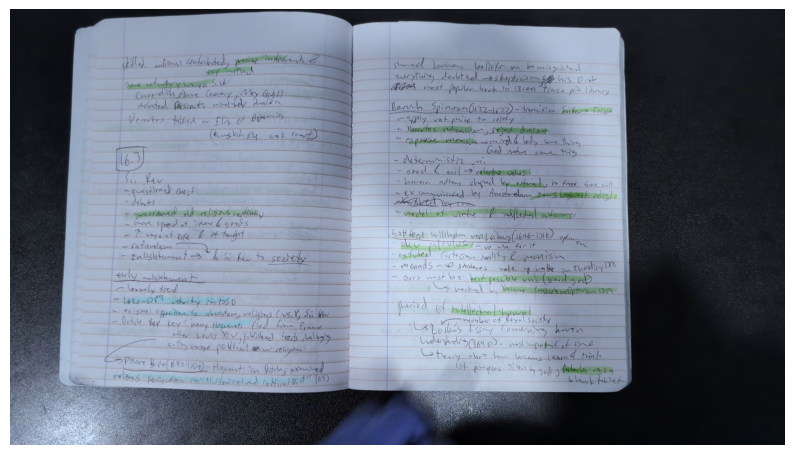

50


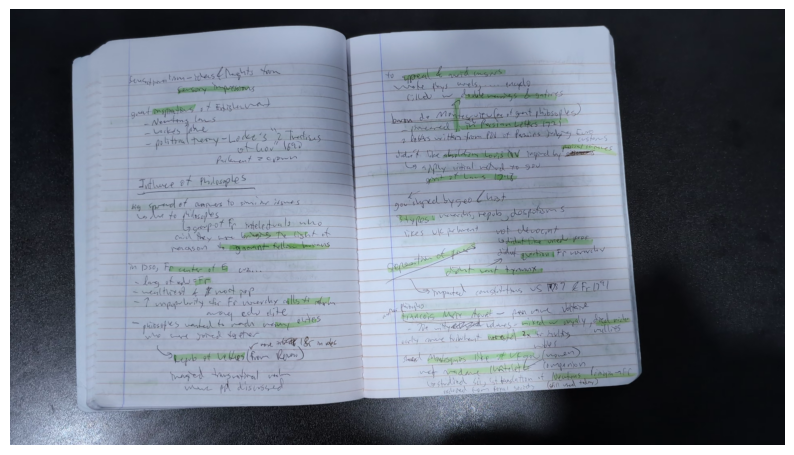

105


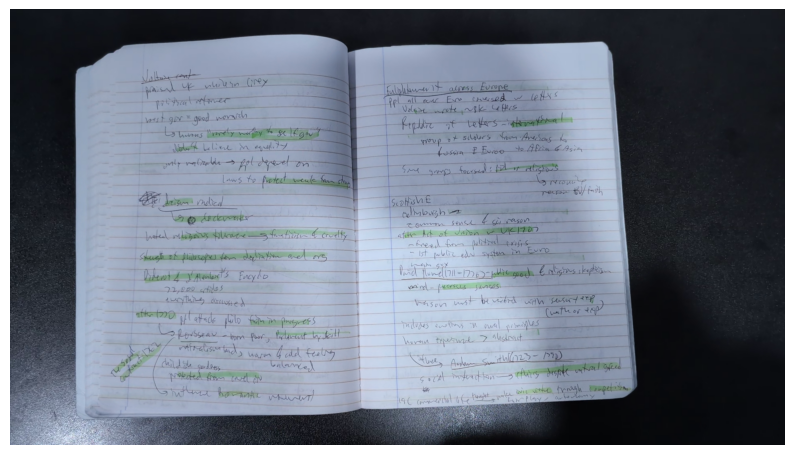

In [15]:
# find the ranges of visible pages which will be the range in the video where a
# page is fully visible. Choose middle frame for final picture
def final_frames(gp):
    ff = []
    i = 0
    while i < len(gp):
        while i < len(gp) and not gp[i]:
            i += 1
        if i >= len(gp) or not gp[i]:
            break
        j = i
        while i+1 < len(gp) and gp[i+1]:
            i += 1
        i += 1
        ff.append((i+j)//2)
    return ff

stt = time.time()
ff = final_frames(goodpg)
print("PREDICTION TOOK: ", time.time()-stt, "seconds")
print(ff)
for i in ff:
    print(i)
    plt.figure(figsize=(10,10))
    plt.imshow(frames[i])
    #draw_rectangle(fin_pg[i], color='r', linewidth=2)
    plt.axis('off')
    plt.show()

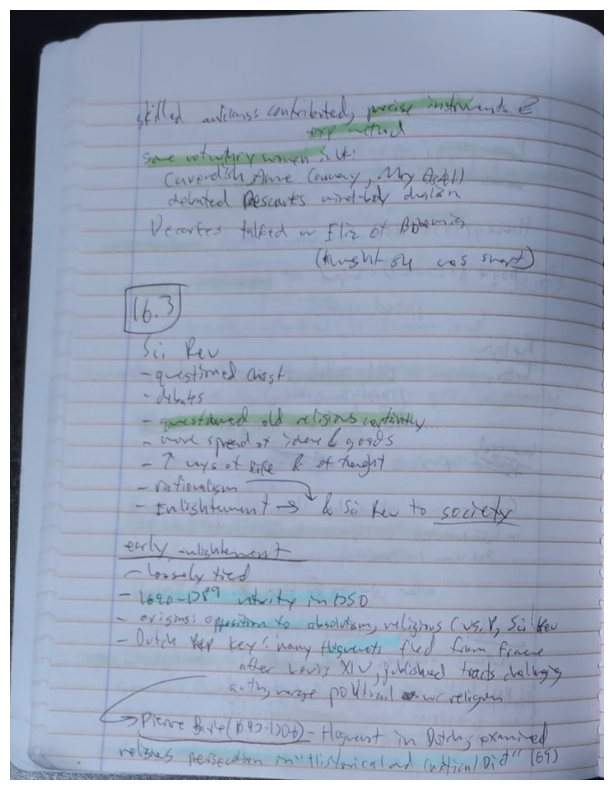

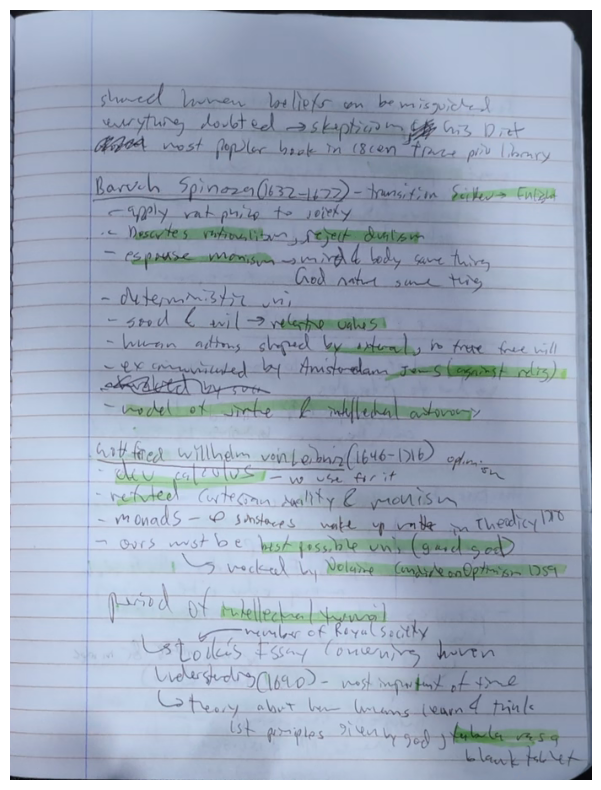

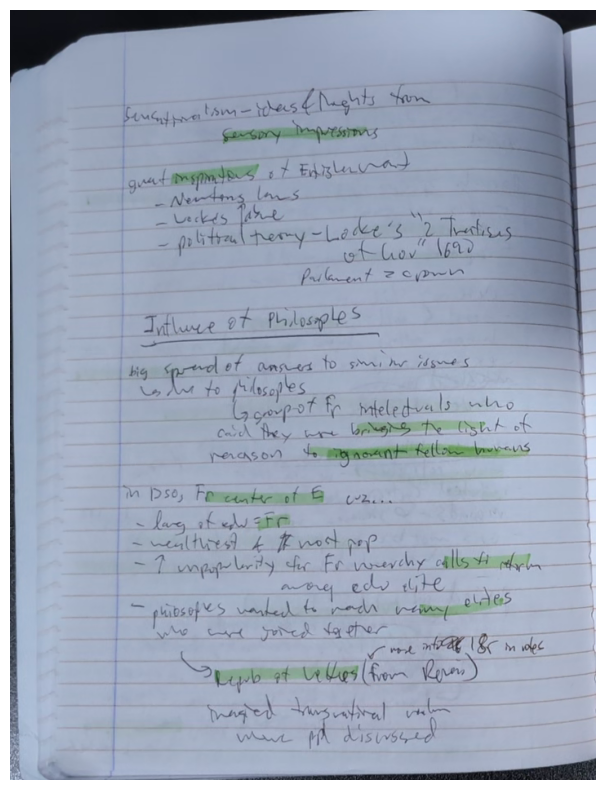

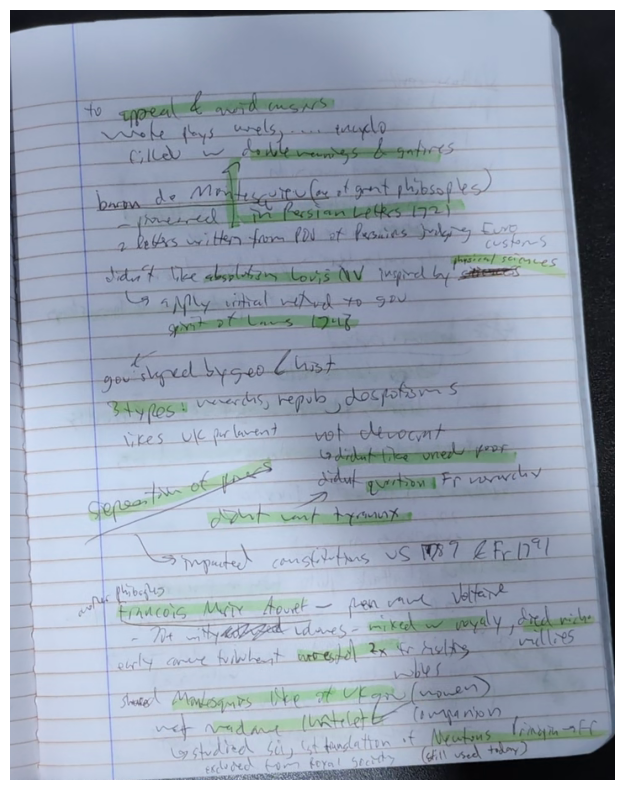

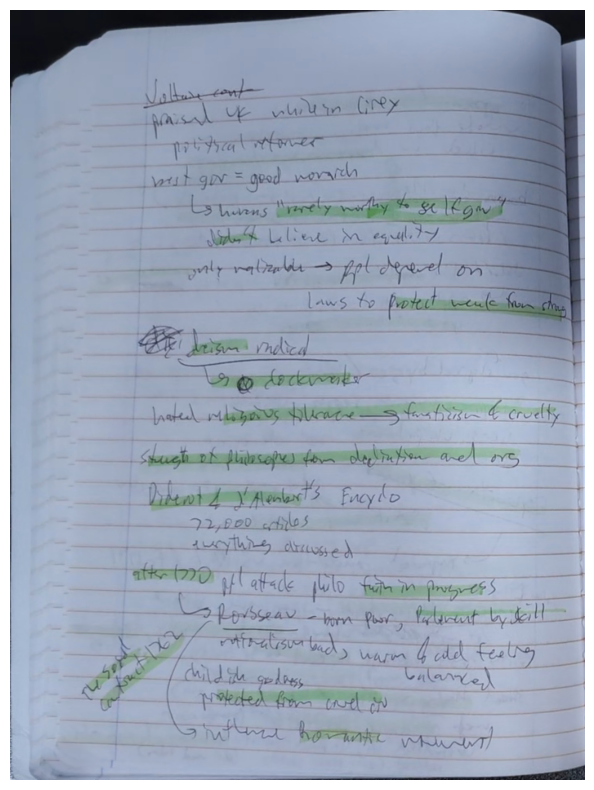

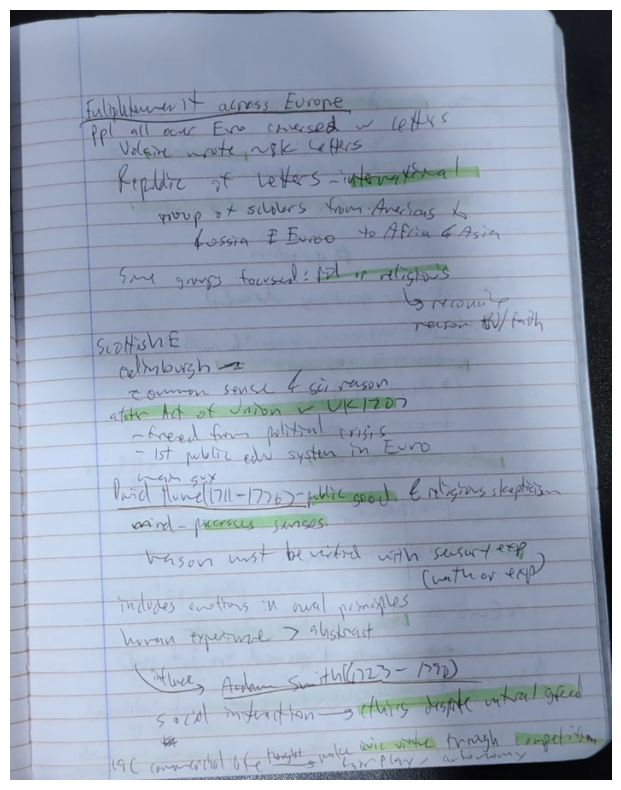

In [16]:
# Final crop of all the pages

for pgi in ff:
    fin_pg[pgi] = sorted(fin_pg[pgi], key=lambda x:x['bbox'][0])
    for i in range(0,len(fin_pg[pgi])):
        fr = frames[pgi]
        bbox = fin_pg[pgi][i]['bbox']

        plt.figure(figsize=(10,10))
        plt.imshow(fr[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]])
        plt.axis('off')
        plt.show()